<img src="https://github.com/FarzadNekouee/Keras-CIFAR10-CNN-Model/blob/master/image.png?raw=true" width="1800">

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:125%; text-align:left">

<h2 align="left"><font color=#8502d1>Dataset CIFAR-10</font></h2>

Dataset ****CIFAR-10**** merupakan dataset yang telah banyak digunakan sebagai tolak ukur dalam bidang machine learning, khususnya untuk ****klasifikasi gambar****. Dataset ini terdiri dari ****60.000 gambar berwarna****, yang masing-masing berukuran ****32x32 piksel****, dan terbagi ke dalam ****10 kelas berbeda****, yang masing-masing merepresentasikan objek atau makhluk yang berbeda. Kelas-kelas tersebut meliputi:

* Pesawat

* Mobil

* Burung

* Kucing

* Rusa

* Anjing

* Katak

* Kuda

* Kapal

* Truk

Setiap kelas memiliki jumlah data yang sama, yaitu 6.000 gambar. Dari total keseluruhan gambar tersebut, 50.000 gambar digunakan untuk proses pelatihan, sedangkan 10.000 gambar sisanya digunakan untuk pengujian.

</div>


<div style="border-radius:12px; padding:20px; background-color:#e2c9ff; font-size:125%; text-align:left">

<h2 align="left"><font color=#8502d1>Tujuan</font></h2>

* <b>Dataset dan Setup</b>

  * Menyiapkan dataset dan lingkungan eksperimen untuk melakukan klasifikasi gambar menggunakan CNN.
  * Melakukan preprocessing dan pembagian dataset sebagai persiapan proses pelatihan dan evaluasi.

* <b>Implementasi Dua Model CNN</b>

  * Mengimplementasikan <b>Model A berupa CNN sederhana</b> sebagai model dasar klasifikasi.
  * Mengimplementasikan <b>Model B dengan residual connection</b> untuk meningkatkan kemampuan pembelajaran jaringan.
  * Melatih kedua model dengan konfigurasi yang sama agar perbandingan performa dapat dilakukan secara adil.

* <b>Eksperimen dan Evaluasi Model</b>

  * Mengevaluasi proses pembelajaran kedua model berdasarkan <b>loss dan accuracy</b> pada data training dan validation.
  * Mengukur <b>akurasi test, jumlah parameter, dan waktu training</b> masing-masing model.
  * Menganalisis hasil klasifikasi menggunakan <b>confusion matrix</b>.
  * Membandingkan performa Model A dan Model B berdasarkan hasil evaluasi.

* <b>Ablation Study</b>

  * Menguji pengaruh salah satu komponen model terhadap performa CNN.
  * Menganalisis perubahan performa dan potensi <b>overfitting</b> berdasarkan hasil eksperimen.

* <b>Analisis dan Pelaporan</b>

  * Menganalisis hasil eksperimen berdasarkan konsep <b>Convolutional Neural Network dan residual connection</b>.
  * Menyajikan hasil eksperimen dalam bentuk <b>tabel, grafik, dan confusion matrix</b>.
  * Mendokumentasikan hasil eksperimen serta melakukan refleksi terhadap proses implementasi.

</div>


<a id="contents_tabel"></a>

<div style="border-radius:10px; padding:15px; background-color:#e2c9ff; font-size:125%; text-align:left">

<h2 align="left"><font color=#8502d1>Table of Contents</font></h2>

* [Step 1 | Dataset and Setup](#setup)
  * [Step 1.1 | Import Libraries](#import)
  * [Step 1.2 | Load and Prepare CIFAR-10 Dataset](#dataset)
  * [Step 1.3 | DataLoader and Hyperparameters](#dataloader)

* [Step 2 | Model Implementation](#model)
  * [Step 2.1 | Model A — Simple CNN](#model_a)
  * [Step 2.2 | Model B — CNN with Residual Connection](#model_b)

* [Step 3 | Experiments and Evaluation](#evaluation)
  * [Step 3.1 | Model A Training and Evaluation](#eval_a)
  * [Step 3.2 | Model B Training and Evaluation](#eval_b)
  * [Step 3.3 | Learning Curves](#curves)
  * [Step 3.4 | Model Performance Comparison](#comparison)

* [Step 4 | Ablation Study — Dropout vs Without Dropout](#ablation)
  * [Step 4.1 | Model A with Dropout](#dropout)
  * [Step 4.2 | Model A without Dropout](#no_dropout)
  * [Step 4.3 | Ablation Analysis](#ablation_analysis)

* [Step 5 | Analysis, Report, and Reflection](#report)
  * [Step 5.1 | Architecture Summary](#architecture)
  * [Step 5.2 | Analysis and Interpretation](#analysis)
  * [Step 5.3 | Reflection](#reflection)

</div>

<a id="setup"></a>
# <p style="background-color:#8502d1; font-family:calibri; color:white; font-size:150%; text-align:center; border-radius:15px 50px;">Step 1 | Dataset and Setup</p>

⬆️ [Tabel of Contents](#contents_tabel)

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Pada tahap ini kita menyiapkan seluruh fondasi eksperimen: mengimpor library, memuat dan menyiapkan dataset **CIFAR-10**, hingga membangun DataLoader beserta hyperparameter yang akan digunakan secara **identik** untuk melatih Model A dan Model B.

</div>

<a id="import"></a>

# <b><span style='color:darkorange'>Step 1.1 |</span><span style='color: #8502d1'> Import Libraries</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Mengimpor seluruh library yang dibutuhkan untuk keseluruhan eksperimen: pemuatan dataset, preprocessing, pembangunan **Model A (Simple CNN)** dan **Model B (Residual CNN)**, proses training, hingga evaluasi (learning curve, confusion matrix, dan perbandingan performa).

</div>

In [ ]:
import warnings
warnings.filterwarnings('ignore')

import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

from tensorflow.keras.datasets import cifar10
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    BatchNormalization,
    Activation,
    Add
)

from tensorflow.keras.regularizers import l2
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau, EarlyStopping

# Reproducibility
import tensorflow as tf

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.20.0


<a id="dataset"></a>

# <b><span style='color:darkorange'>Step 1.2 |</span><span style='color: #8502d1'> Load and Prepare CIFAR-10 Dataset</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Memuat dataset CIFAR-10 bawaan Keras (50.000 gambar training, 10.000 gambar test):

</div>

In [ ]:
(X_train_full, y_train_full), (X_test, y_test) = cifar10.load_data()

print('Full Train Images Shape:', X_train_full.shape)
print('Full Train Labels Shape:', y_train_full.shape)
print('Test Images Shape:      ', X_test.shape)
print('Test Labels Shape:      ', y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 165s 1us/step
Full Train Images Shape: (50000, 32, 32, 3)
Full Train Labels Shape: (50000, 1)
Test Images Shape:       (10000, 32, 32, 3)
Test Labels Shape:       (10000, 1)


<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Melihat sekilas isi dataset — contoh gambar tiap kelas dan distribusi jumlah data per kelas — sebelum data diproses lebih lanjut:

</div>

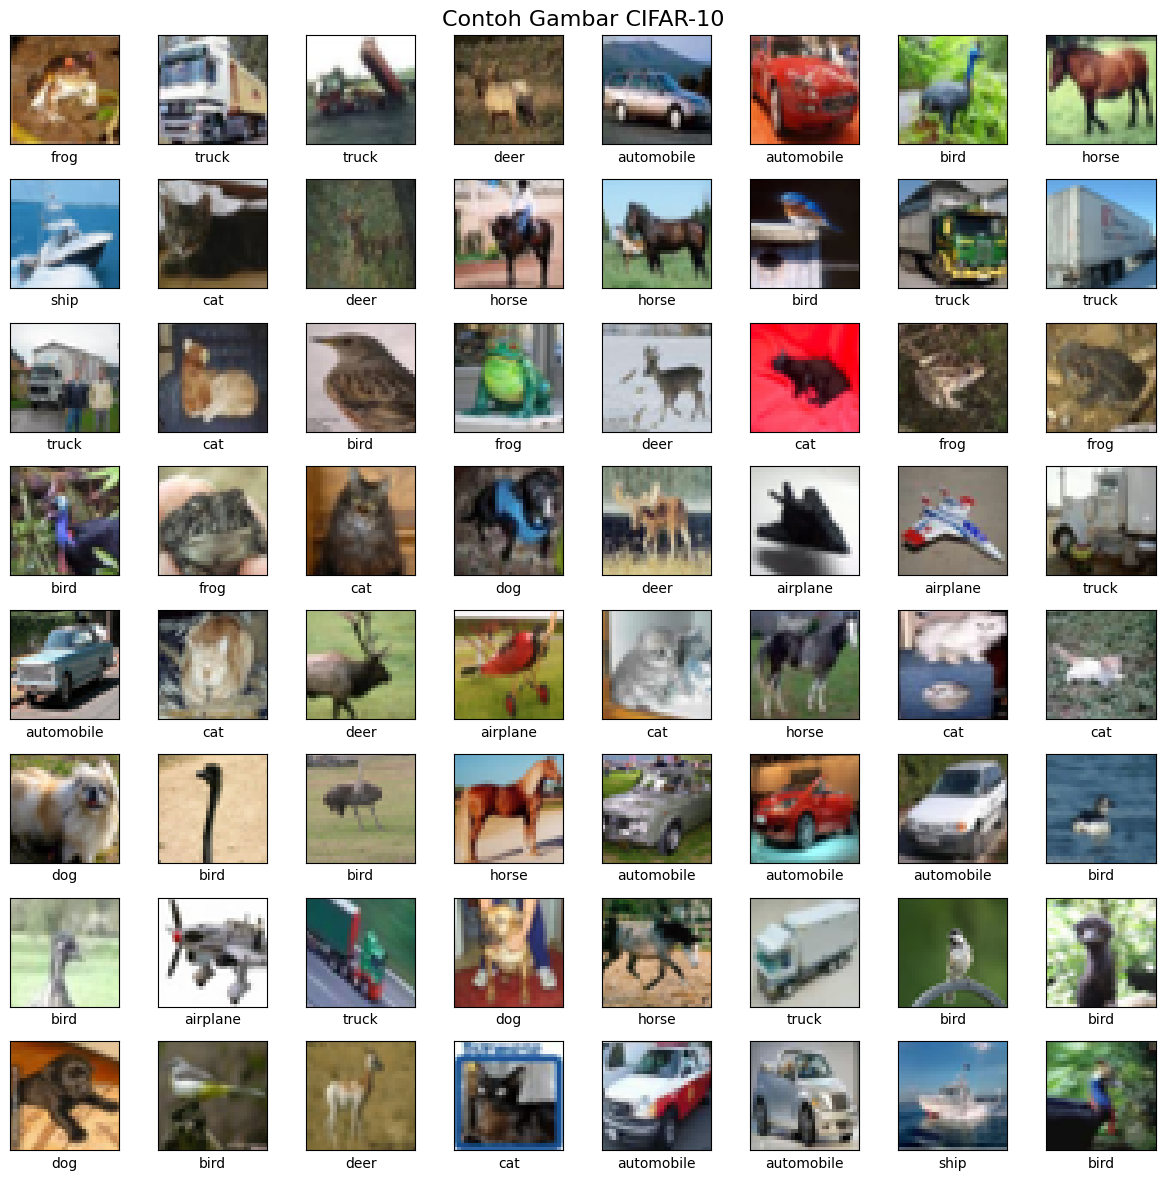

In [ ]:
class_names = ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']

plt.figure(figsize=(12, 12))
for i in range(64):
    plt.subplot(8, 8, i + 1)
    plt.xticks([]); plt.yticks([]); plt.grid(False)
    plt.imshow(X_train_full[i])
    plt.xlabel(class_names[int(y_train_full[i])])
plt.suptitle('Contoh Gambar CIFAR-10', fontsize=16)
plt.tight_layout()
plt.show()

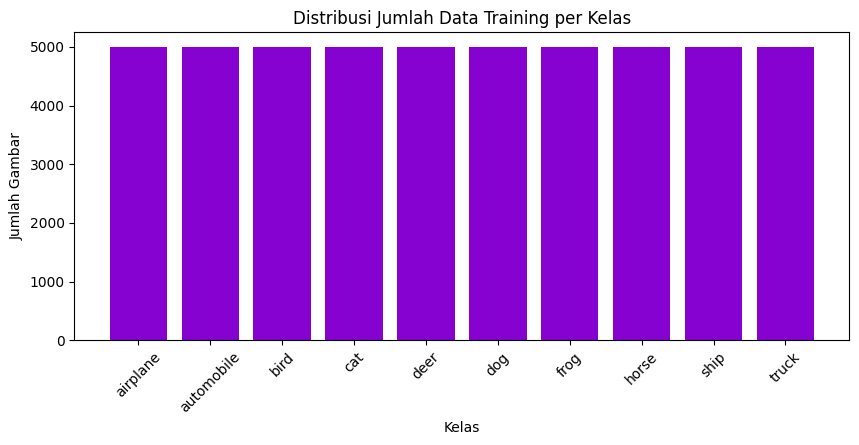

In [ ]:
unique, counts = np.unique(y_train_full, return_counts=True)

plt.figure(figsize=(10, 4))
plt.bar([class_names[i] for i in unique], counts, color='#8502d1')
plt.title('Distribusi Jumlah Data Training per Kelas')
plt.xlabel('Kelas'); plt.ylabel('Jumlah Gambar')
plt.xticks(rotation=45)
plt.show()

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Normalisasi.** Mengubah tipe data piksel menjadi `float32`, lalu menormalisasi menggunakan mean dan std yang dihitung **hanya dari data training** agar tidak terjadi *data leakage* dari data test:

</div>

In [ ]:
X_train_full = X_train_full.astype('float32')
X_test = X_test.astype('float32')

mean = np.mean(X_train_full)
std = np.std(X_train_full)

X_train_full = (X_train_full - mean) / (std + 1e-7)
X_test = (X_test - mean) / (std + 1e-7)

print(f'Mean: {mean:.4f}, Std: {std:.4f}')

Mean: 120.7075, Std: 64.1500


<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**One-Hot Encoding.** Mengonversi label kelas menjadi vektor one-hot untuk klasifikasi multi-kelas:

</div>

In [ ]:
NUM_CLASSES = 10

y_train_full_oh = to_categorical(y_train_full, NUM_CLASSES)
y_test_oh = to_categorical(y_test, NUM_CLASSES)

print('y_train_full_oh shape:', y_train_full_oh.shape)
print('y_test_oh shape:      ', y_test_oh.shape)

y_train_full_oh shape: (50000, 10)
y_test_oh shape:       (10000, 10)


<a id="dataloader"></a>

# <b><span style='color:darkorange'>Step 1.3 |</span><span style='color: #8502d1'> DataLoader and Hyperparameters</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Membagi data training menjadi **training set** dan **validation set** (90:10), mendefinisikan **data augmentation**, lalu menyiapkan DataLoader (`ImageDataGenerator.flow`) beserta hyperparameter yang akan digunakan secara **identik** untuk melatih Model A dan Model B — sehingga perbandingan performa keduanya adil.

</div>

In [ ]:
X_train, X_valid, y_train, y_valid = train_test_split(
    X_train_full, y_train_full_oh, test_size=0.1, random_state=SEED
)

print('Train Images Shape:      ', X_train.shape)
print('Validation Images Shape: ', X_valid.shape)
print('Test Images Shape:       ', X_test.shape)

Train Images Shape:       (45000, 32, 32, 3)
Validation Images Shape:  (5000, 32, 32, 3)
Test Images Shape:        (10000, 32, 32, 3)


In [ ]:
# Data augmentation - dipakai identik untuk training Model A maupun Model B
data_generator = ImageDataGenerator(
    rotation_range=15,        # Rotasi acak hingga 15 derajat
    width_shift_range=0.12,   # Pergeseran horizontal hingga 12% lebar gambar
    height_shift_range=0.12,  # Pergeseran vertikal hingga 12% tinggi gambar
    horizontal_flip=True,     # Flip horizontal secara acak
    zoom_range=0.1            # Zoom acak hingga 10%
)
data_generator.fit(X_train)

In [ ]:
# Hyperparameter bersama (digunakan identik untuk Model A dan Model B)
BATCH_SIZE = 64
EPOCHS = 15
LEARNING_RATE = 0.001
WEIGHT_DECAY = 1e-4

train_generator = data_generator.flow(X_train, y_train, batch_size=BATCH_SIZE, seed=SEED)
steps_per_epoch = int(np.ceil(len(X_train) / BATCH_SIZE))

print(f'Batch size       : {BATCH_SIZE}')
print(f'Epochs (max)     : {EPOCHS}')
print(f'Learning rate    : {LEARNING_RATE}')
print(f'Weight decay     : {WEIGHT_DECAY}')
print(f'Steps per epoch  : {steps_per_epoch}')

Batch size       : 64
Epochs (max)     : 15
Learning rate    : 0.001
Weight decay     : 0.0001
Steps per epoch  : 704


In [ ]:
def get_callbacks():
    """Membuat instance callback baru dengan parameter identik untuk setiap training run."""
    reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=5, min_lr=1e-6, verbose=1)
    early_stopping = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True, verbose=1)
    return [reduce_lr, early_stopping]

<a id="model"></a>
# <p style="background-color:#8502d1; font-family:calibri; color:white; font-size:150%; text-align:center; border-radius:15px 50px;">Step 2 | Model Implementation</p>

⬆️ [Tabel of Contents](#contents_tabel)

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Dua arsitektur CNN diimplementasikan pada tahap ini: **Model A** sebagai CNN sederhana (*baseline*, tanpa residual connection) dan **Model B** sebagai CNN dengan residual connection. Kedua model dibuat dengan kedalaman dan jumlah filter yang setara (32 → 64 → 128), sehingga perbedaan performa yang muncul nantinya dapat lebih diatribusikan pada **ada/tidaknya residual connection**, bukan pada perbedaan kapasitas model.

</div>

<a id="model_a"></a>

# <b><span style='color:darkorange'>Step 2.1 |</span><span style='color: #8502d1'> Model A — Simple CNN</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Model A** terdiri dari 3 blok Conv-BatchNorm-ReLU-Pooling (masing-masing 2 layer konvolusi) dengan filter 32 → 64 → 128, diikuti fully connected layer dan output klasifikasi 10 kelas. Parameter `use_dropout` disediakan agar arsitektur ini dapat langsung dipakai ulang pada **Ablation Study (Step 4)** tanpa duplikasi kode.

</div>

In [ ]:
def conv_block(x, filters, weight_decay=WEIGHT_DECAY):
    """Blok Conv-BatchNorm-ReLU standar (tanpa residual connection)."""
    x = Conv2D(
        filters,
        (3, 3),
        padding='same',
        kernel_regularizer=l2(weight_decay)
    )(x)
    x = BatchNormalization()(x)
    x = Activation('relu')(x)
    return x


def build_model_a(
    input_shape=(32, 32, 3),
    num_classes=NUM_CLASSES,
    use_dropout=True
):
    """
    Model A: Custom CNN tanpa residual connection.

    Terdiri dari 4 blok konvolusi:
    Conv -> BatchNorm -> ReLU -> Pooling

    Dropout dapat diaktifkan/dinonaktifkan untuk Ablation Study.
    """

    inputs = Input(shape=input_shape, name='input_model_a')

    # =========================
    # Blok 1
    # =========================
    x = conv_block(inputs, 32)
    x = conv_block(x, 32)
    x = MaxPooling2D(pool_size=(2, 2))(x)

    if use_dropout:
        x = Dropout(0.2)(x)

    # =========================
    # Blok 2
    # =========================
    x = conv_block(x, 64)
    x = conv_block(x, 64)
    x = MaxPooling2D(pool_size=(2, 2))(x)

    if use_dropout:
        x = Dropout(0.3)(x)

    # =========================
    # Blok 3
    # =========================
    x = conv_block(x, 128)
    x = conv_block(x, 128)
    x = MaxPooling2D(pool_size=(2, 2))(x)

    if use_dropout:
        x = Dropout(0.4)(x)

    # =========================
    # Blok 4
    # =========================
    x = conv_block(x, 256)
    x = conv_block(x, 256)

    # =========================
    # Global Average Pooling
    # =========================
    x = GlobalAveragePooling2D()(x)

    # =========================
    # Fully Connected
    # =========================
    x = Dense(
        128,
        activation='relu',
        kernel_regularizer=l2(WEIGHT_DECAY)
    )(x)

    if use_dropout:
        x = Dropout(0.5)(x)

    # =========================
    # Output
    # =========================
    outputs = Dense(
        num_classes,
        activation='softmax'
    )(x)

    model = Model(
        inputs=inputs,
        outputs=outputs,
        name='Model_A_Simple_CNN'
    )

    return model


# Membuat Model A dengan Dropout
model_a = build_model_a(use_dropout=True)

print(f'Total Parameter Model A: {model_a.count_params():,}')

model_a.summary()

Total Parameter Model A: 1,210,282


Model: "Model_A_Simple_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_model_a (InputLayer)      │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_4 (Activation)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 128)      │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │             

 Total params: 1,210,282 (4.62 MB)

 Trainable params: 1,208,362 (4.61 MB)

 Non-trainable params: 1,920 (7.50 KB)

<a id="model_b"></a>

# <b><span style='color:darkorange'>Step 2.2 |</span><span style='color: #8502d1'> Model B — CNN with Residual Connection</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Model B** menggunakan kedalaman dan jumlah filter yang setara dengan Model A, namun setiap blok diimplementasikan sebagai **residual block** dengan *skip connection* (terinspirasi dari ResNet).

</div>

In [ ]:
def residual_block(x, filters, weight_decay=WEIGHT_DECAY):
    """Blok residual sederhana: 2x Conv-BN-ReLU dengan skip connection (identity/projection)."""
    shortcut = x

    y = Conv2D(filters, (3, 3), padding='same', kernel_regularizer=l2(weight_decay))(x)
    y = BatchNormalization()(y)
    y = Activation('relu')(y)

    y = Conv2D(filters, (3, 3), padding='same', kernel_regularizer=l2(weight_decay))(y)
    y = BatchNormalization()(y)

    # Proyeksi shortcut jika jumlah channel berubah
    if shortcut.shape[-1] != filters:
        shortcut = Conv2D(filters, (1, 1), padding='same', kernel_regularizer=l2(weight_decay))(shortcut)
        shortcut = BatchNormalization()(shortcut)

    out = Add()([shortcut, y])
    out = Activation('relu')(out)
    return out


def build_model_b(input_shape=(32, 32, 3), num_classes=NUM_CLASSES):
    """Model B: CNN dengan residual connection (mini-ResNet), setara kedalaman dengan Model A."""
    inputs = Input(shape=input_shape, name='input_model_b')

    x = residual_block(inputs, 32)
    x = MaxPooling2D(pool_size=(2, 2))(x)
    x = Dropout(0.2)(x)

    x = residual_block(x, 64)
    x = MaxPooling2D(pool_size=(2, 2))(x)
    x = Dropout(0.3)(x)

    x = residual_block(x, 128)
    x = MaxPooling2D(pool_size=(2, 2))(x)
    x = Dropout(0.4)(x)

    x = GlobalAveragePooling2D()(x)
    x = Dense(128, activation='relu', kernel_regularizer=l2(WEIGHT_DECAY))(x)
    x = Dropout(0.5)(x)
    outputs = Dense(num_classes, activation='softmax')(x)

    model = Model(inputs=inputs, outputs=outputs, name='Model_B_Residual_CNN')
    return model


model_b = build_model_b()
print(f'Total Parameter Model B: {model_b.count_params():,}')
model_b.summary()

Total Parameter Model B: 318,058


Model: "Model_B_Residual_CNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_model_b       │ (None, 32, 32, 3) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 32, 32,    │        896 │ input_model_b[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_8[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_8        │ (None, 32, 32,    │          0 │ batch_normalizat… │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_10 (Conv2D)  │ (None, 32, 32,    │        128 │ input_model_b[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 32, 32,    │      9,248 │ activation_8[0][… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_10[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        128 │ conv2d_9[0][0]    │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 32)               │            │ batch_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_9        │ (None, 32, 32,    │          0 │ add[0][0]         │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 16, 16,    │          0 │ activation_9[0][… │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_4 (Dropout) │ (None, 16, 16,    │          0 │ max_pooling2d_3[… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 16, 16,    │     18,496 │ dropout_4[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │        256 │ conv2d_11[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activation_10       │ (None, 16, 16,    │          0 │ batch_normalizat… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 16, 16,    │      2,112 │ dropout_4[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 16, 16,    │     36,928 │ activation_10[0]

 Total params: 318,058 (1.21 MB)

 Trainable params: 316,714 (1.21 MB)

 Non-trainable params: 1,344 (5.25 KB)

<a id="evaluation"></a>
# <p style="background-color:#8502d1; font-family:calibri; color:white; font-size:150%; text-align:center; border-radius:15px 50px;">Step 3 | Experiments and Evaluation</p>

⬆️ [Tabel of Contents](#contents_tabel)

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Model A dan Model B dilatih menggunakan **hyperparameter, data generator, dan skema callback yang identik** (lihat Step 1.3), lalu masing-masing langsung dievaluasi: training/validation loss & accuracy, test accuracy, jumlah parameter, waktu training, dan confusion matrix. Hasil keduanya kemudian dibandingkan pada Step 3.3-3.4.

</div>

<a id="eval_a"></a>

# <b><span style='color:darkorange'>Step 3.1 |</span><span style='color: #8502d1'> Model A Training and Evaluation</span></b>

In [ ]:
model_a.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

start_time_a = time.time()

history_a = model_a.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_valid, y_valid),
    callbacks=get_callbacks(),
    verbose=1
)

training_time_a = time.time() - start_time_a
print(f'\nWaktu training Model A: {training_time_a:.2f} detik ({training_time_a/60:.2f} menit)')

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 254s 357ms/step - accuracy: 0.4080 - loss: 1.7266 - val_accuracy: 0.5102 - val_loss: 1.5093 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 247s 351ms/step - accuracy: 0.5438 - loss: 1.4084 - val_accuracy: 0.5898 - val_loss: 1.3368 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 247s 352ms/step - accuracy: 0.6028 - loss: 1.2667 - val_accuracy: 0.6204 - val_loss: 1.1998 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 246s 350ms/step - accuracy: 0.6451 - loss: 1.1683 - val_accuracy: 0.7140 - val_loss: 0.9407 - learning_rate: 0.0010
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 247s 351ms/step - accuracy: 0.6715 - loss: 1.1013 - val_accuracy: 0.6472 - val_loss: 1.2098 - learning_rate: 0.0010
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 247s 351ms/step - accuracy: 0.6894 - loss: 1.0670 - val_accuracy: 0.7572 - val_loss: 0.8425 - learning_rate: 0.0010
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 247s 350ms/step - accura

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Evaluasi Model A** — test accuracy, jumlah parameter, dan confusion matrix:

</div>

In [ ]:
test_loss_a, test_acc_a = model_a.evaluate(X_test, y_test_oh, verbose=0)
params_a = model_a.count_params()

print('Model A (Simple CNN)')
print(f'  Test Accuracy    : {test_acc_a * 100:.2f}% ({test_acc_a:.4f})')
print(f'  Test Loss        : {test_loss_a:.4f}')
print(f'  Total Parameter  : {params_a:,}')
print(f'  Waktu Training   : {training_time_a:.2f} detik')
print(f'  Epoch efektif    : {len(history_a.history["loss"])}')

Model A (Simple CNN)
  Test Accuracy    : 81.75% (0.8175)
  Test Loss        : 0.7085
  Total Parameter  : 1,210,282
  Waktu Training   : 3709.79 detik
  Epoch efektif    : 15


<Figure size 800x800 with 0 Axes>

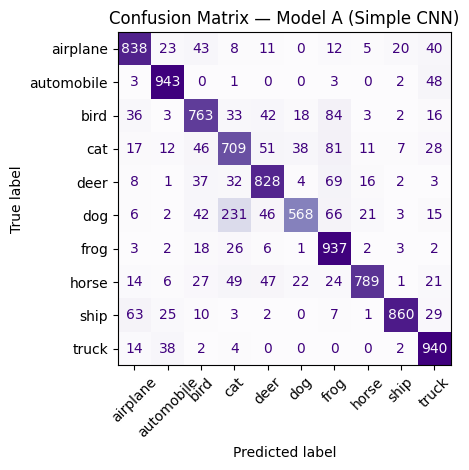

              precision    recall  f1-score   support

    airplane       0.84      0.84      0.84      1000
  automobile       0.89      0.94      0.92      1000
        bird       0.77      0.76      0.77      1000
         cat       0.65      0.71      0.68      1000
        deer       0.80      0.83      0.81      1000
         dog       0.87      0.57      0.69      1000
        frog       0.73      0.94      0.82      1000
       horse       0.93      0.79      0.85      1000
        ship       0.95      0.86      0.90      1000
       truck       0.82      0.94      0.88      1000

    accuracy                           0.82     10000
   macro avg       0.83      0.82      0.82     10000
weighted avg       0.83      0.82      0.82     10000



In [ ]:
y_pred_a = np.argmax(model_a.predict(X_test, verbose=0), axis=1)
y_true = y_test.flatten()

cm_a = confusion_matrix(y_true, y_pred_a)

plt.figure(figsize=(8, 8))
disp_a = ConfusionMatrixDisplay(confusion_matrix=cm_a, display_labels=class_names)
disp_a.plot(cmap='Purples', colorbar=False, xticks_rotation=45)
plt.title('Confusion Matrix — Model A (Simple CNN)')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred_a, target_names=class_names))

<a id="eval_b"></a>

# <b><span style='color:darkorange'>Step 3.2 |</span><span style='color: #8502d1'> Model B Training and Evaluation</span></b>

In [ ]:
model_b.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

start_time_b = time.time()

history_b = model_b.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_valid, y_valid),
    callbacks=get_callbacks(),
    verbose=1
)

training_time_b = time.time() - start_time_b
print(f'\nWaktu training Model B: {training_time_b:.2f} detik ({training_time_b/60:.2f} menit)')

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 239s 334ms/step - accuracy: 0.3696 - loss: 1.7786 - val_accuracy: 0.4304 - val_loss: 1.6171 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 235s 334ms/step - accuracy: 0.4981 - loss: 1.4572 - val_accuracy: 0.5842 - val_loss: 1.2182 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 235s 333ms/step - accuracy: 0.5549 - loss: 1.3272 - val_accuracy: 0.5868 - val_loss: 1.2194 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 235s 334ms/step - accuracy: 0.5848 - loss: 1.2470 - val_accuracy: 0.6078 - val_loss: 1.2075 - learning_rate: 0.0010
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 234s 333ms/step - accuracy: 0.6153 - loss: 1.1889 - val_accuracy: 0.6046 - val_loss: 1.2199 - learning_rate: 0.0010
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 235s 334ms/step - accuracy: 0.6412 - loss: 1.1279 - val_accuracy: 0.6144 - val_loss: 1.2691 - learning_rate: 0.0010
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 234s 333ms/step - accura

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Evaluasi Model B** — test accuracy, jumlah parameter, dan confusion matrix:

</div>

In [ ]:
test_loss_b, test_acc_b = model_b.evaluate(X_test, y_test_oh, verbose=0)
params_b = model_b.count_params()

print('Model B (Residual CNN)')
print(f'  Test Accuracy    : {test_acc_b * 100:.2f}% ({test_acc_b:.4f})')
print(f'  Test Loss        : {test_loss_b:.4f}')
print(f'  Total Parameter  : {params_b:,}')
print(f'  Waktu Training   : {training_time_b:.2f} detik')
print(f'  Epoch efektif    : {len(history_b.history["loss"])}')

Model B (Residual CNN)
  Test Accuracy    : 79.11% (0.7911)
  Test Loss        : 0.7588
  Total Parameter  : 318,058
  Waktu Training   : 3524.07 detik
  Epoch efektif    : 15


<Figure size 800x800 with 0 Axes>

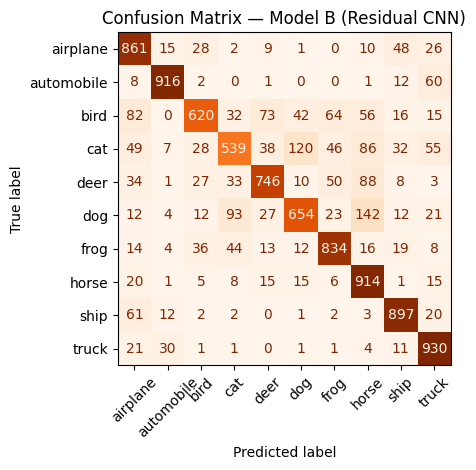

              precision    recall  f1-score   support

    airplane       0.74      0.86      0.80      1000
  automobile       0.93      0.92      0.92      1000
        bird       0.81      0.62      0.70      1000
         cat       0.71      0.54      0.61      1000
        deer       0.81      0.75      0.78      1000
         dog       0.76      0.65      0.70      1000
        frog       0.81      0.83      0.82      1000
       horse       0.69      0.91      0.79      1000
        ship       0.85      0.90      0.87      1000
       truck       0.81      0.93      0.86      1000

    accuracy                           0.79     10000
   macro avg       0.79      0.79      0.79     10000
weighted avg       0.79      0.79      0.79     10000



In [ ]:
y_pred_b = np.argmax(model_b.predict(X_test, verbose=0), axis=1)

cm_b = confusion_matrix(y_true, y_pred_b)

plt.figure(figsize=(8, 8))
disp_b = ConfusionMatrixDisplay(confusion_matrix=cm_b, display_labels=class_names)
disp_b.plot(cmap='Oranges', colorbar=False, xticks_rotation=45)
plt.title('Confusion Matrix — Model B (Residual CNN)')
plt.tight_layout()
plt.show()

print(classification_report(y_true, y_pred_b, target_names=class_names))

<a id="curves"></a>

# <b><span style='color:darkorange'>Step 3.3 |</span><span style='color: #8502d1'> Learning Curves</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Membandingkan kurva **training vs validation loss** dan **training vs validation accuracy** kedua model:

</div>

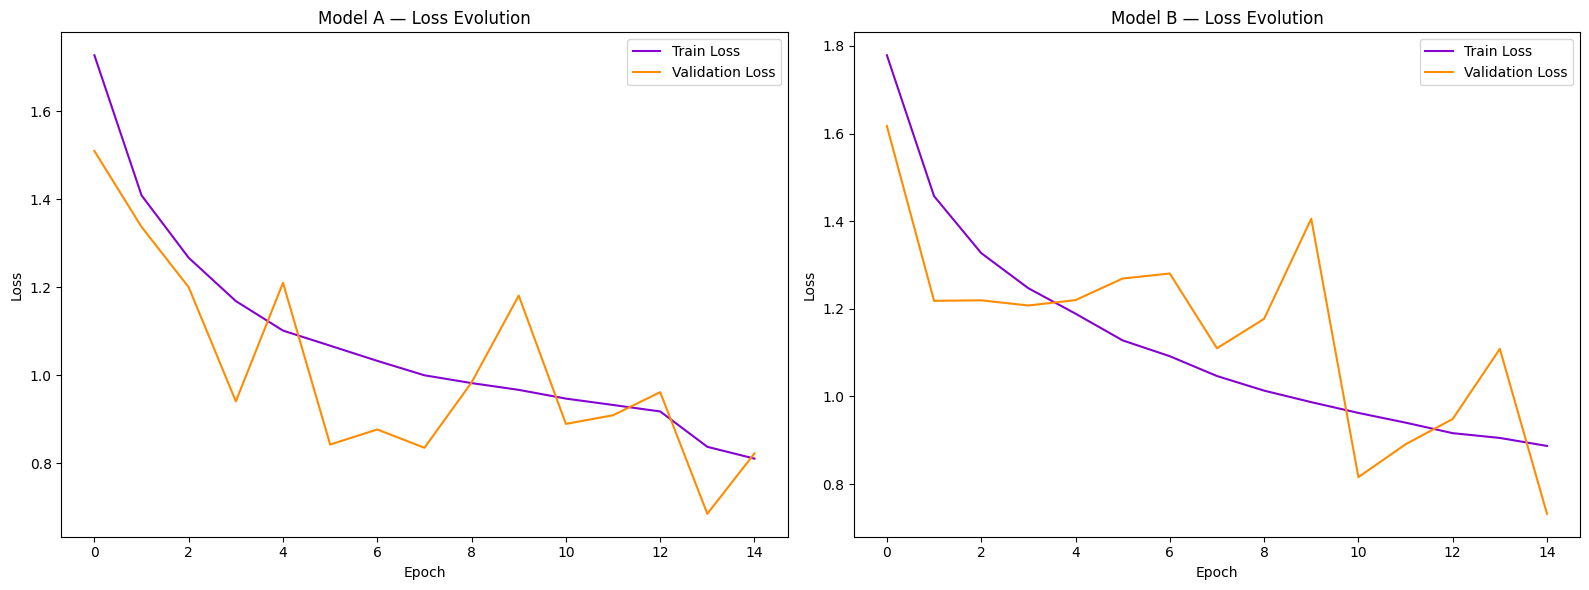

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(history_a.history['loss'], label='Train Loss', color='#8502d1')
axes[0].plot(history_a.history['val_loss'], label='Validation Loss', color='darkorange')
axes[0].set_title('Model A — Loss Evolution')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(history_b.history['loss'], label='Train Loss', color='#8502d1')
axes[1].plot(history_b.history['val_loss'], label='Validation Loss', color='darkorange')
axes[1].set_title('Model B — Loss Evolution')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss'); axes[1].legend()

plt.tight_layout()
plt.show()

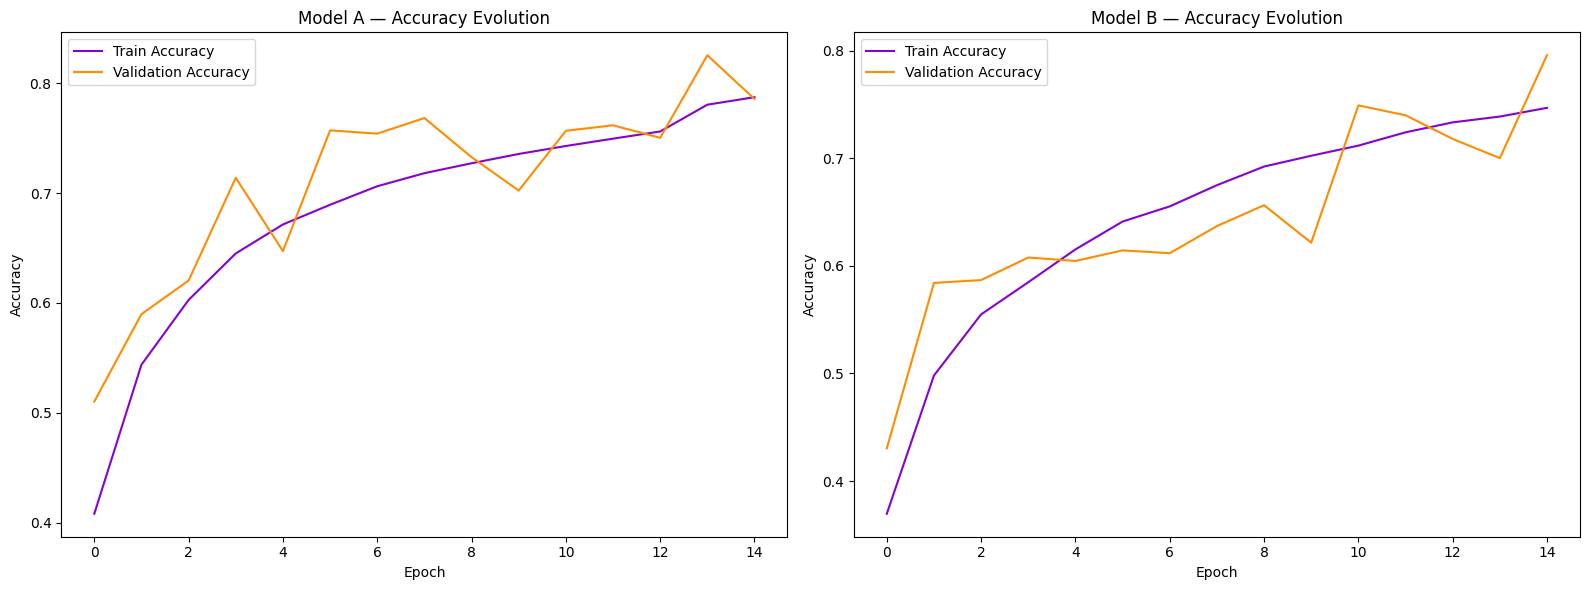

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

axes[0].plot(history_a.history['accuracy'], label='Train Accuracy', color='#8502d1')
axes[0].plot(history_a.history['val_accuracy'], label='Validation Accuracy', color='darkorange')
axes[0].set_title('Model A — Accuracy Evolution')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy'); axes[0].legend()

axes[1].plot(history_b.history['accuracy'], label='Train Accuracy', color='#8502d1')
axes[1].plot(history_b.history['val_accuracy'], label='Validation Accuracy', color='darkorange')
axes[1].set_title('Model B — Accuracy Evolution')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.show()

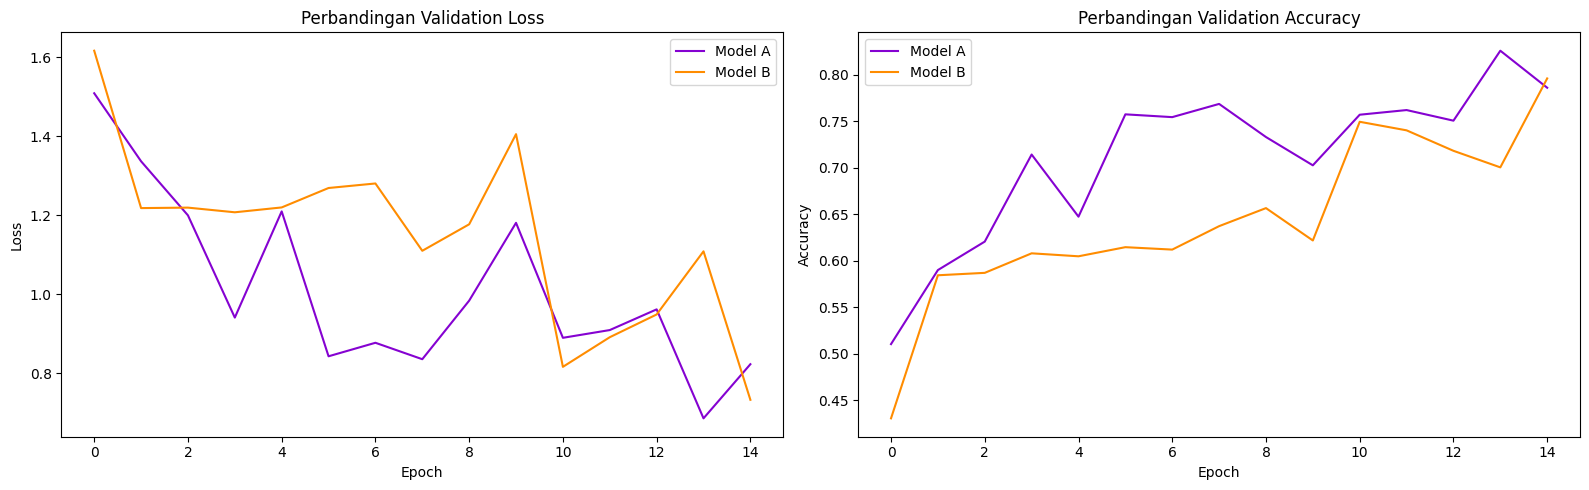

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

axes[0].plot(history_a.history['val_loss'], label='Model A', color='#8502d1')
axes[0].plot(history_b.history['val_loss'], label='Model B', color='darkorange')
axes[0].set_title('Perbandingan Validation Loss')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend()

axes[1].plot(history_a.history['val_accuracy'], label='Model A', color='#8502d1')
axes[1].plot(history_b.history['val_accuracy'], label='Model B', color='darkorange')
axes[1].set_title('Perbandingan Validation Accuracy')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy'); axes[1].legend()

plt.tight_layout()
plt.show()

<a id="comparison"></a>

# <b><span style='color:darkorange'>Step 3.4 |</span><span style='color: #8502d1'> Model Performance Comparison</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Merangkum seluruh metrik penting Model A dan Model B ke dalam satu tabel perbandingan:

</div>

In [ ]:
comparison_df = pd.DataFrame({
    'Metrik': [
        'Test Accuracy', 'Test Loss', 'Best Val Accuracy', 'Best Val Loss',
        'Jumlah Parameter', 'Waktu Training (detik)', 'Jumlah Epoch Efektif'
    ],
    'Model A (Simple CNN)': [
        f'{test_acc_a*100:.2f}%', f'{test_loss_a:.4f}',
        f'{max(history_a.history["val_accuracy"])*100:.2f}%', f'{min(history_a.history["val_loss"]):.4f}',
        f'{params_a:,}', f'{training_time_a:.2f}', len(history_a.history["loss"])
    ],
    'Model B (Residual CNN)': [
        f'{test_acc_b*100:.2f}%', f'{test_loss_b:.4f}',
        f'{max(history_b.history["val_accuracy"])*100:.2f}%', f'{min(history_b.history["val_loss"]):.4f}',
        f'{params_b:,}', f'{training_time_b:.2f}', len(history_b.history["loss"])
    ]
})

comparison_df

,Metrik,Model A (Simple CNN),Model B (Residual CNN)
0,Test Accuracy,81.75%,79.11%
1,Test Loss,0.7085,0.7588
2,Best Val Accuracy,82.56%,79.58%
3,Best Val Loss,0.6853,0.7322
4,Jumlah Parameter,"1,210,282","318,058"
5,Waktu Training (detik),3709.79,3524.07
6,Jumlah Epoch Efektif,15,15


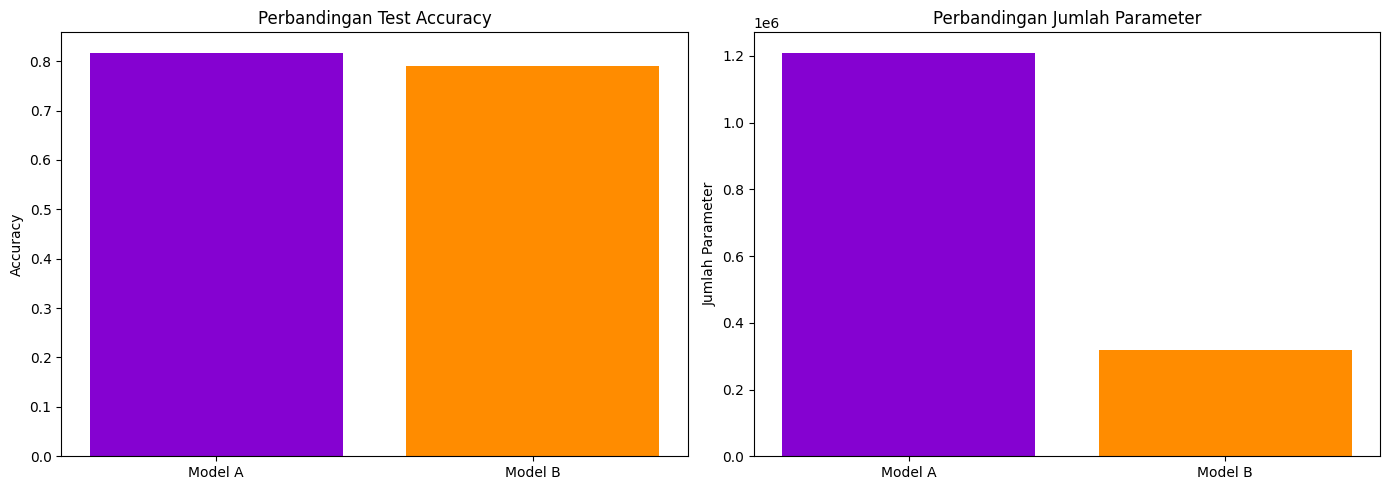

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(['Model A', 'Model B'], [test_acc_a, test_acc_b], color=['#8502d1', 'darkorange'])
axes[0].set_title('Perbandingan Test Accuracy')
axes[0].set_ylabel('Accuracy')

axes[1].bar(['Model A', 'Model B'], [params_a, params_b], color=['#8502d1', 'darkorange'])
axes[1].set_title('Perbandingan Jumlah Parameter')
axes[1].set_ylabel('Jumlah Parameter')

plt.tight_layout()
plt.show()

<a id="ablation"></a>
# <p style="background-color:#8502d1; font-family:calibri; color:white; font-size:150%; text-align:center; border-radius:15px 50px;">Step 4 | Ablation Study — Dropout vs Without Dropout</p>

⬆️ [Tabel of Contents](#contents_tabel)

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Ablation study** dilakukan pada **Model A (Simple CNN)** dengan membandingkan performa model **dengan Dropout** (arsitektur asli pada Step 2.1) versus **tanpa Dropout** sama sekali, menggunakan fungsi `build_model_a(use_dropout=...)` yang sudah disiapkan di Step 2.1. Kedua varian dilatih dengan **hyperparameter, data, dan callback yang identik** agar perbandingan tetap adil. Tujuannya untuk mengetahui seberapa besar kontribusi Dropout terhadap **potensi overfitting** dan performa akhir model.

</div>

<a id="dropout"></a>

# <b><span style='color:darkorange'>Step 4.1 |</span><span style='color: #8502d1'> Model A with Dropout</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Melatih ulang varian Model A **dengan Dropout** secara independen agar eksperimen ablation ini berdiri sendiri (self-contained):

</div>

In [34]:
model_a_dropout = build_model_a(use_dropout=True)

model_a_dropout.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

start_time_dropout = time.time()

history_a_dropout = model_a_dropout.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_valid, y_valid),
    callbacks=get_callbacks(),
    verbose=1
)

training_time_dropout = time.time() - start_time_dropout

test_loss_dropout, test_acc_dropout = model_a_dropout.evaluate(X_test, y_test_oh, verbose=0)
print(f'\nModel A dengan Dropout -> Test Accuracy: {test_acc_dropout*100:.2f}%, Test Loss: {test_loss_dropout:.4f}')

Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 63s 67ms/step - accuracy: 0.4249 - loss: 1.6933 - val_accuracy: 0.4598 - val_loss: 1.6966 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 35s 50ms/step - accuracy: 0.5571 - loss: 1.3748 - val_accuracy: 0.5660 - val_loss: 1.3783 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.6163 - loss: 1.2273 - val_accuracy: 0.5740 - val_loss: 1.3706 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 35s 49ms/step - accuracy: 0.6571 - loss: 1.1354 - val_accuracy: 0.6772 - val_loss: 1.0819 - learning_rate: 0.0010
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 53ms/step - accuracy: 0.6821 - loss: 1.0899 - val_accuracy: 0.6608 - val_loss: 1.1760 - learning_rate: 0.0010
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 50ms/step - accuracy: 0.6943 - loss: 1.0574 - val_accuracy: 0.6934 - val_loss: 1.0267 - learning_rate: 0.0010
Epoch 7/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.7065 - l

<a id="no_dropout"></a>

# <b><span style='color:darkorange'>Step 4.2 |</span><span style='color: #8502d1'> Model A without Dropout</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Melatih varian Model A **tanpa Dropout sama sekali**, dengan hyperparameter dan callback yang identik:

</div>

In [ ]:
model_a_no_dropout = build_model_a(use_dropout=False)
print(f'Total Parameter Model A tanpa Dropout: {model_a_no_dropout.count_params():,}')

model_a_no_dropout.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

start_time_no_dropout = time.time()

history_a_no_dropout = model_a_no_dropout.fit(
    train_generator,
    steps_per_epoch=steps_per_epoch,
    epochs=EPOCHS,
    validation_data=(X_valid, y_valid),
    callbacks=get_callbacks(),
    verbose=1
)

training_time_no_dropout = time.time() - start_time_no_dropout

test_loss_no_dropout, test_acc_no_dropout = model_a_no_dropout.evaluate(X_test, y_test_oh, verbose=0)
print(f'\nModel A tanpa Dropout -> Test Accuracy: {test_acc_no_dropout*100:.2f}%, Test Loss: {test_loss_no_dropout:.4f}')

Total Parameter Model A tanpa Dropout: 1,210,282
Epoch 1/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 63s 66ms/step - accuracy: 0.5139 - loss: 1.4433 - val_accuracy: 0.5304 - val_loss: 1.4369 - learning_rate: 0.0010
Epoch 2/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 36s 52ms/step - accuracy: 0.6620 - loss: 1.0757 - val_accuracy: 0.6054 - val_loss: 1.2518 - learning_rate: 0.0010
Epoch 3/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.7164 - loss: 0.9402 - val_accuracy: 0.6596 - val_loss: 1.1935 - learning_rate: 0.0010
Epoch 4/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 35s 50ms/step - accuracy: 0.7422 - loss: 0.8798 - val_accuracy: 0.7546 - val_loss: 0.8492 - learning_rate: 0.0010
Epoch 5/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 42s 52ms/step - accuracy: 0.7651 - loss: 0.8281 - val_accuracy: 0.7364 - val_loss: 0.9302 - learning_rate: 0.0010
Epoch 6/15
704/704 ━━━━━━━━━━━━━━━━━━━━ 37s 52ms/step - accuracy: 0.7783 - loss: 0.7945 - val_accuracy: 0.7116 - val_loss: 1.0076 - learning_rate: 0.0010
Epoch 7/15
704/704 ━━━━━━━━

Amankan hasil ke drive mvuehehe (kalau blm)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pickle

with open('/content/drive/MyDrive/history_a_dropout.pkl', 'wb') as f:
    pickle.dump(history_a_dropout.history, f)

print("History Dropout tersimpan.")


Mounted at /content/drive
History Dropout tersimpan.


In [35]:
from google.colab import drive
drive.mount('/content/drive')

import pickle

dropout_results = {
    'history': history_a_dropout.history,
    'test_accuracy': test_acc_dropout,
    'test_loss': test_loss_dropout,
    'training_time': training_time_dropout
}

with open('/content/drive/MyDrive/dropout_results.pkl', 'wb') as f:
    pickle.dump(dropout_results, f)

print("Semua hasil Model A dengan Dropout berhasil disimpan!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Semua hasil Model A dengan Dropout berhasil disimpan!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import pickle

no_dropout_results = {
    'history': history_a_no_dropout.history,
    'test_accuracy': test_acc_no_dropout,
    'test_loss': test_loss_no_dropout,
    'training_time': training_time_no_dropout
}

with open('/content/drive/MyDrive/no_dropout_results.pkl', 'wb') as f:
    pickle.dump(no_dropout_results, f)

print("Semua hasil Model A Tanpa Dropout berhasil disimpan!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Semua hasil Model A Tanpa Dropout berhasil disimpan!


<a id="ablation_analysis"></a>

# <b><span style='color:darkorange'>Step 4.3 |</span><span style='color: #8502d1'> Ablation Analysis</span></b>

ambil hasil yang tersimpan didrive

In [47]:
import pickle

dropout_results = {
    'test_accuracy': test_acc_dropout,
    'test_loss': test_loss_dropout,
    'training_time': training_time_dropout
}

with open('/content/drive/MyDrive/dropout_results.pkl', 'wb') as f:
    pickle.dump(dropout_results, f)

print("Semua hasil Dropout berhasil disimpan!")

Semua hasil Dropout berhasil disimpan!


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("Isi MyDrive:")
for root, dirs, files in os.walk('/content/drive/MyDrive'):
    for file in files:
        if 'dropout' in file.lower():
            print(os.path.join(root, file))


            import pickle

path = '/content/drive/MyDrive/history_a_dropout.pkl'

with open(path, 'rb') as f:
    dropout_history = pickle.load(f)

print("History Dropout berhasil dimuat!")
print(dropout_history.keys())
print("Jumlah epoch:", len(dropout_history['accuracy']))
print("Train Accuracy terakhir:", dropout_history['accuracy'][-1])
print("Val Accuracy terakhir:", dropout_history['val_accuracy'][-1])

Mounted at /content/drive
Isi MyDrive:
/content/drive/MyDrive/history_a_dropout.pkl
History Dropout berhasil dimuat!
dict_keys(['accuracy', 'loss', 'val_accuracy', 'val_loss', 'learning_rate'])
Jumlah epoch: 15
Train Accuracy terakhir: 0.7831777930259705
Val Accuracy terakhir: 0.7878000140190125


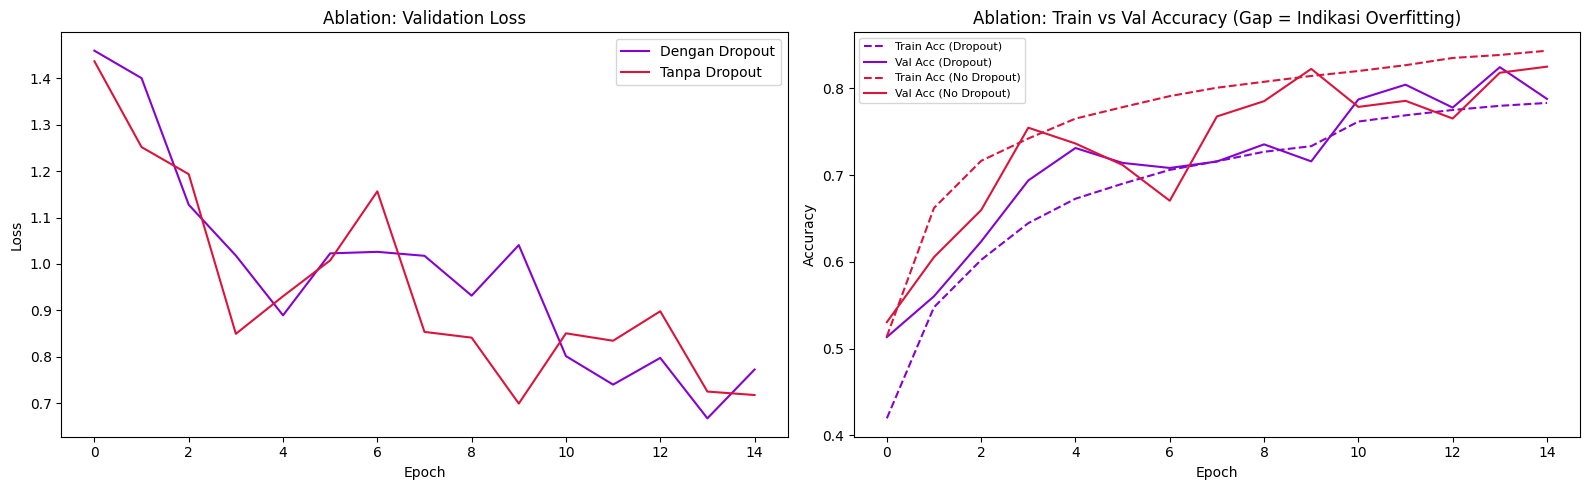

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Validation Loss
axes[0].plot(
    dropout_history['val_loss'],
    label='Dengan Dropout',
    color='#8502d1'
)

axes[0].plot(
    history_a_no_dropout.history['val_loss'],
    label='Tanpa Dropout',
    color='crimson'
)

axes[0].set_title('Ablation: Validation Loss')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()


# Train vs Validation Accuracy
axes[1].plot(
    dropout_history['accuracy'],
    label='Train Acc (Dropout)',
    color='#8502d1',
    linestyle='--'
)

axes[1].plot(
    dropout_history['val_accuracy'],
    label='Val Acc (Dropout)',
    color='#8502d1'
)

axes[1].plot(
    history_a_no_dropout.history['accuracy'],
    label='Train Acc (No Dropout)',
    color='crimson',
    linestyle='--'
)

axes[1].plot(
    history_a_no_dropout.history['val_accuracy'],
    label='Val Acc (No Dropout)',
    color='crimson'
)

axes[1].set_title('Ablation: Train vs Val Accuracy (Gap = Indikasi Overfitting)')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

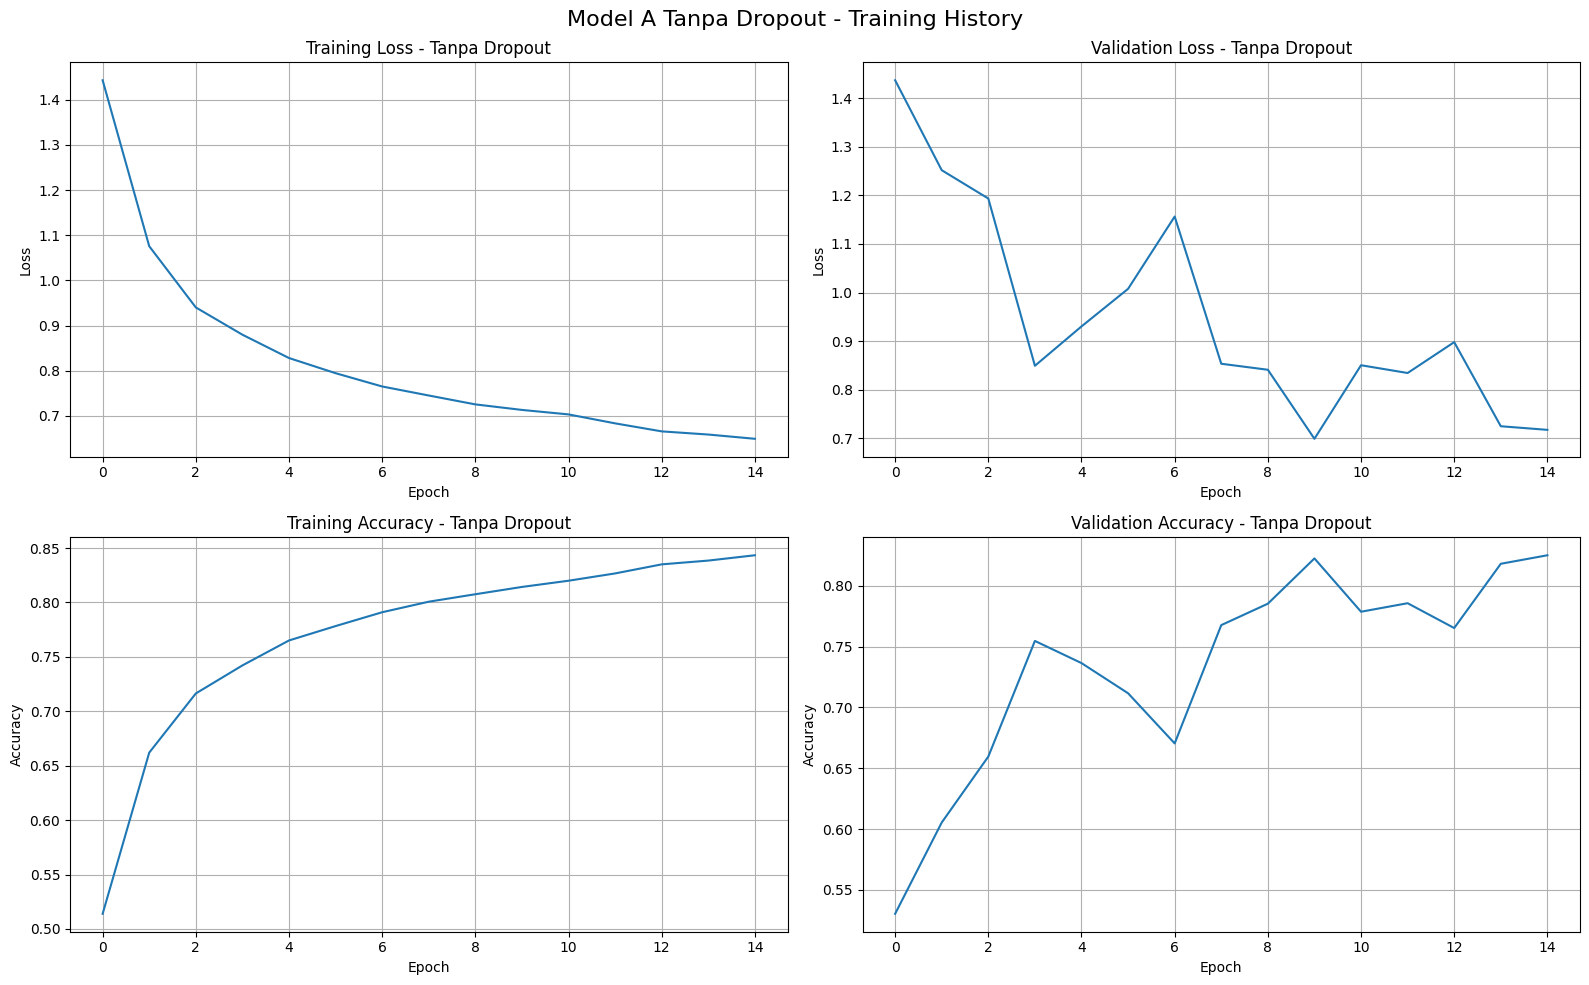

In [ ]:
import matplotlib.pyplot as plt

history = no_dropout_results['history']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Training Loss
axes[0, 0].plot(history['loss'])
axes[0, 0].set_title('Training Loss - Tanpa Dropout')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].grid(True)

# 2. Validation Loss
axes[0, 1].plot(history['val_loss'])
axes[0, 1].set_title('Validation Loss - Tanpa Dropout')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].grid(True)

# 3. Training Accuracy
axes[1, 0].plot(history['accuracy'])
axes[1, 0].set_title('Training Accuracy - Tanpa Dropout')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].grid(True)

# 4. Validation Accuracy
axes[1, 1].plot(history['val_accuracy'])
axes[1, 1].set_title('Validation Accuracy - Tanpa Dropout')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].grid(True)

fig.suptitle(
    'Model A Tanpa Dropout - Training History',
    fontsize=16
)

plt.tight_layout()
plt.show()

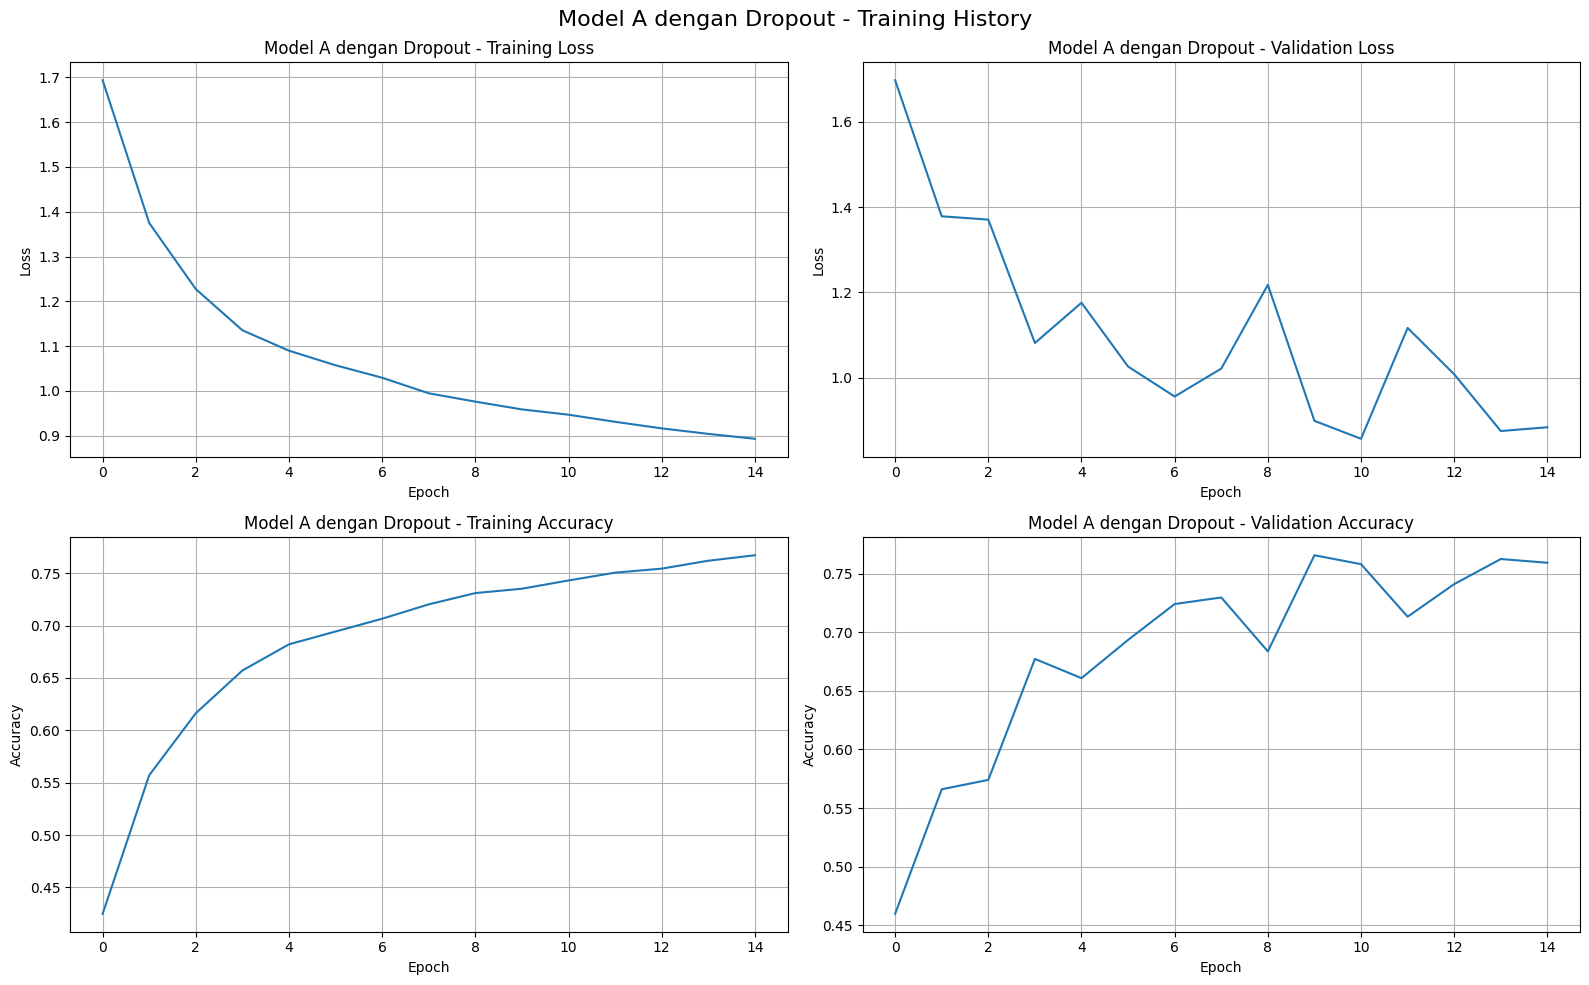

In [51]:
import matplotlib.pyplot as plt

# Ambil history yang masih ada di runtime
dropout_history = history_a_dropout.history

# Buat 4 grafik
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# 1. Training Loss
axes[0, 0].plot(dropout_history['loss'])
axes[0, 0].set_title('Model A dengan Dropout - Training Loss')
axes[0, 0].set_xlabel('Epoch')
axes[0, 0].set_ylabel('Loss')
axes[0, 0].grid(True)

# 2. Validation Loss
axes[0, 1].plot(dropout_history['val_loss'])
axes[0, 1].set_title('Model A dengan Dropout - Validation Loss')
axes[0, 1].set_xlabel('Epoch')
axes[0, 1].set_ylabel('Loss')
axes[0, 1].grid(True)

# 3. Training Accuracy
axes[1, 0].plot(dropout_history['accuracy'])
axes[1, 0].set_title('Model A dengan Dropout - Training Accuracy')
axes[1, 0].set_xlabel('Epoch')
axes[1, 0].set_ylabel('Accuracy')
axes[1, 0].grid(True)

# 4. Validation Accuracy
axes[1, 1].plot(dropout_history['val_accuracy'])
axes[1, 1].set_title('Model A dengan Dropout - Validation Accuracy')
axes[1, 1].set_xlabel('Epoch')
axes[1, 1].set_ylabel('Accuracy')
axes[1, 1].grid(True)

plt.suptitle(
    'Model A dengan Dropout - Training History',
    fontsize=16
)

plt.tight_layout()
plt.show()

<h3 align="left"><font color=#8502d1>🎯 Insight Ablation Study:</font></h3>

* **Gap antara training accuracy dan validation accuracy** yang lebih besar pada varian *tanpa Dropout* mengindikasikan model tersebut lebih **overfitting** terhadap data training.

* Jika *test accuracy* varian *dengan Dropout* lebih tinggi atau sebanding namun dengan gap yang lebih kecil, ini menunjukkan Dropout berhasil berperan sebagai regularisasi yang membantu generalisasi model.

* Jika perbedaannya kecil, kemungkinan augmentasi data dan Batch Normalization yang sudah ada pada Model A sudah cukup memberikan efek regularisasi, sehingga peran tambahan Dropout menjadi relatif kecil.

<a id="report"></a>
# <p style="background-color:#8502d1; font-family:calibri; color:white; font-size:150%; text-align:center; border-radius:15px 50px;">Step 5 | Analysis, Report, and Reflection</p>

⬆️ [Tabel of Contents](#contents_tabel)

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Tahap terakhir ini merangkum arsitektur kedua model, menganalisis seluruh hasil eksperimen (termasuk hasil ablation study), dan menutup dengan refleksi proses eksperimen secara keseluruhan.

</div>

<a id="architecture"></a>

# <b><span style='color:darkorange'>Step 5.1 |</span><span style='color: #8502d1'> Architecture Summary</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Ringkasan perbandingan struktural antara Model A dan Model B:

</div>

In [54]:
params_a = model_a.count_params()
params_b = model_b.count_params()

print(f"Parameter Model A: {params_a:,}")
print(f"Parameter Model B: {params_b:,}")

Parameter Model A: 1,210,282
Parameter Model B: 318,058


In [55]:
architecture_df = pd.DataFrame({

    'Aspek Arsitektur': [

        'Jumlah Blok Konvolusi', 'Progresi Filter', 'Residual / Skip Connection',

        'Batch Normalization', 'Pooling/Downsampling Layer', 'Global Pooling',

        'Regularisasi', 'Total Parameter'

    ],

    'Model A (Simple CNN)': [

        '4 blok (2 conv/blok)', '32 -> 64 -> 128 -> 256', 'Tidak ada',

        'Ada (tiap conv)', 'MaxPooling2D x3', 'Ada (GlobalAveragePooling2D)',

        'L2 + Dropout', f'{params_a:,}'

    ],

    'Model B (Residual CNN)': [

        '3 residual block (2 conv/blok)', '32 -> 64 -> 128', 'Ada (identity/projection shortcut)',

        'Ada (tiap conv)', 'MaxPooling2D x3', 'Ada (GlobalAveragePooling2D)',

        'L2 + Dropout', f'{params_b:,}'

    ]

})

architecture_df

,Aspek Arsitektur,Model A (Simple CNN),Model B (Residual CNN)
0,Jumlah Blok Konvolusi,4 blok (2 conv/blok),3 residual block (2 conv/blok)
1,Progresi Filter,32 -> 64 -> 128 -> 256,32 -> 64 -> 128
2,Residual / Skip Connection,Tidak ada,Ada (identity/projection shortcut)
3,Batch Normalization,Ada (tiap conv),Ada (tiap conv)
4,Pooling/Downsampling Layer,MaxPooling2D x3,MaxPooling2D x3
5,Global Pooling,Ada (GlobalAveragePooling2D),Ada (GlobalAveragePooling2D)
6,Regularisasi,L2 + Dropout,L2 + Dropout
7,Total Parameter,"1,210,282","318,058"


<a id="analysis"></a>

# <b><span style='color:darkorange'>Step 5.2 |</span><span style='color: #8502d1'> Analysis and Interpretation</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

Analisis berikut dihitung secara otomatis berdasarkan hasil eksperimen di atas, sehingga kesimpulan selalu konsisten dengan angka hasil eksekusi terbaru.

</div>

In [43]:
from tensorflow.keras.optimizers import Adam

# Compile ulang Model A
model_a.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Compile ulang Model B
model_b.compile(
    optimizer=Adam(learning_rate=LEARNING_RATE),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

# Hitung jumlah parameter
params_a = model_a.count_params()
params_b = model_b.count_params()

# Evaluasi Model A dan B
test_loss_a, test_acc_a = model_a.evaluate(
    X_test, y_test_oh, verbose=0
)

test_loss_b, test_acc_b = model_b.evaluate(
    X_test, y_test_oh, verbose=0
)

print("=== HASIL EVALUASI ===")
print(f"Model A - Test Accuracy : {test_acc_a*100:.2f}%")
print(f"Model A - Test Loss     : {test_loss_a:.4f}")
print(f"Model A - Parameters    : {params_a:,}")
print()
print(f"Model B - Test Accuracy : {test_acc_b*100:.2f}%")
print(f"Model B - Test Loss     : {test_loss_b:.4f}")
print(f"Model B - Parameters    : {params_b:,}")

=== HASIL EVALUASI ===
Model A - Test Accuracy : 9.89%
Model A - Test Loss     : 2.3983
Model A - Parameters    : 1,210,282

Model B - Test Accuracy : 9.03%
Model B - Test Loss     : 2.3894
Model B - Parameters    : 318,058


In [44]:
params_a = model_a.count_params()
params_b = model_b.count_params()

test_loss_a, test_acc_a = model_a.evaluate(X_test, y_test_oh, verbose=0)
test_loss_b, test_acc_b = model_b.evaluate(X_test, y_test_oh, verbose=0)

print(f"Model A Test Accuracy : {test_acc_a*100:.2f}%")
print(f"Model B Test Accuracy : {test_acc_b*100:.2f}%")
print(f"Model A Parameters    : {params_a:,}")
print(f"Model B Parameters    : {params_b:,}")

Model A Test Accuracy : 9.89%
Model B Test Accuracy : 9.03%
Model A Parameters    : 1,210,282
Model B Parameters    : 318,058


In [46]:
better_model = 'Model B (Residual CNN)' if test_acc_b > test_acc_a else 'Model A (Simple CNN)'

acc_gap = abs(test_acc_b - test_acc_a) * 100
param_diff = params_b - params_a

print(f'>> Model dengan test accuracy lebih tinggi : {better_model}')
print(f'>> Selisih test accuracy                  : {acc_gap:.2f}%')
print(f'>> Selisih jumlah parameter (B - A)       : {param_diff:,}')

print()

if test_acc_b > test_acc_a:
    print('Model B unggul dibandingkan Model A. Hal ini konsisten dengan teori bahwa')
    print('koneksi residual (skip connection) membantu aliran gradien pada jaringan')
    print('yang lebih dalam dan dapat memudahkan proses optimisasi.')
else:
    print('Pada eksperimen ini, Model A menyamai atau mengungguli Model B. Hal ini')
    print('dapat terjadi karena CIFAR-10 memiliki resolusi kecil (32x32) dan arsitektur')
    print('yang digunakan belum cukup dalam untuk memperoleh manfaat residual secara signifikan.')

>> Model dengan test accuracy lebih tinggi : Model A (Simple CNN)
>> Selisih test accuracy                  : 0.86%
>> Selisih jumlah parameter (B - A)       : -892,224

Pada eksperimen ini, Model A menyamai atau mengungguli Model B. Hal ini
dapat terjadi karena CIFAR-10 memiliki resolusi kecil (32x32) dan arsitektur
yang digunakan belum cukup dalam untuk memperoleh manfaat residual secara signifikan.


<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Poin-poin analisis lanjutan yang perlu didiskusikan berdasarkan hasil di atas:**

* Bandingkan **kecepatan konvergensi** dari learning curve (Step 3.3) — model mana yang mencapai validation loss rendah lebih cepat?

* Lihat **confusion matrix** (Step 3.1 & 3.2) — apakah ada kelas tertentu (misalnya *cat* vs *dog*, atau *automobile* vs *truck*) yang lebih sering salah klasifikasi pada salah satu model?

* Hubungkan hasil **Ablation Study Dropout** (Step 4) dengan performa Model A secara umum — apakah overfitting menjadi masalah signifikan pada arsitektur ini?

* Simpulkan **trade-off** antara akurasi, jumlah parameter, dan waktu training: apakah tambahan kompleksitas arsitektur pada Model B sepadan dengan peningkatan performanya?

</div>

<a id="reflection"></a>

# <b><span style='color:darkorange'>Step 5.3 |</span><span style='color: #8502d1'> Reflection</span></b>

<div style="border-radius:12px; padding: 20px; background-color: #e2c9ff; font-size:120%; text-align:left">

**Refleksi Eksperimen**

* **Tantangan yang dihadapi:** Tantangan utama selama eksperimen adalah keterbatasan resource dan waktu training pada Google Colab GPU. Proses training CNN membutuhkan waktu yang cukup lama, sehingga jumlah epoch perlu disesuaikan agar eksperimen Model A, Model B, dan ablation study dapat diselesaikan. Selain itu, beberapa kali terjadi runtime reset yang menyebabkan variabel dan hasil eksperimen di memori hilang. Oleh karena itu, hasil training perlu disimpan secara berkala agar tidak perlu melakukan training ulang dari awal.

* **Hal yang dapat diperbaiki:** Pada eksperimen selanjutnya, proses penyimpanan checkpoint, model, dan history training dapat dibuat lebih konsisten untuk mengantisipasi runtime reset. Jika resource GPU lebih memadai, jumlah epoch dapat ditingkatkan sehingga model memiliki kesempatan untuk melakukan pembelajaran lebih optimal. Selain itu, dapat dilakukan pengujian arsitektur residual dengan kedalaman berbeda serta variasi optimizer atau strategi augmentasi untuk memperoleh perbandingan yang lebih luas.

* **Pembelajaran utama:** Eksperimen menunjukkan bahwa penggunaan residual connection tidak selalu menghasilkan akurasi yang lebih tinggi. Model A yang telah ditingkatkan kapasitasnya dengan empat blok konvolusi mampu menghasilkan performa yang kompetitif terhadap Model B yang menggunakan residual connection. Hal ini menunjukkan bahwa performa model dipengaruhi oleh kombinasi kapasitas arsitektur, regularisasi, optimasi, dan karakteristik dataset, bukan hanya penggunaan residual connection. Ablation study juga memberikan pemahaman mengenai peran Dropout sebagai teknik regularisasi untuk membantu mengendalikan overfitting.

</div>

<div style="display: flex; align-items: center; justify-content: center; border-radius: 10px; padding: 20px; background-color:  #e2c9ff; font-size: 120%; text-align: center;">

<strong>🎯 If you need more information or want to explore the code, feel free to visit the project repository on <a href="https://github.com/FarzadNekouee/Keras-CIFAR10-CNN-Model">GitHub</a> 🎯</strong>
</div>


<h2 align="left"><font color='#8502d1'>Best Regards!</font></h2>